# Construcción y evaluación del modelo (entrega final, ítem 10)

La rúbrica pide entrenar **al menos tres algoritmos con distintos conjuntos de hiperparámetros**, reportar la evaluación cuantitativa con las métricas del enfoque analítico, complementarla con una evaluación cualitativa y proponer oportunidades de mejora.

Se sigue el protocolo definido en `validacion_particion.ipynb` (ítem 9), sin cambiarlo después de ver resultados:

| Paso | Datos | Criterio |
|---|---|---|
| 1. Hiperparámetros | entrenamiento (hasta 2.000 días por cuenca) → validación | NSE mediano por cuenca |
| 2. Algoritmo | validación cruzada espacial (5 folds) sobre el periodo de validación | NSE mediano espacial; a menos de 0,02 del mejor, el más simple |
| 3. Prueba, una vez | entrenamiento + validación → prueba | KPIs P4–P9 del primer reporte |

**Algoritmos.** Regresión lineal con regularización (Ridge), Random Forest y gradient boosting (`HistGradientBoostingRegressor`), todos dentro de un `Pipeline` con el preprocesamiento de la Práctica 6. El LSTM del primer reporte **no se entrena**: no se vio en clase y no hay aprobación de los docentes; queda como oportunidad de mejora.

**Reproducir.** `python codigo/modelado.py` entrena todo y guarda en `salidas/modelos/` (alrededor de una hora); este notebook solo lee esos resultados.

| Sección | Qué se hace |
|---|---|
| 1 | Búsqueda de hiperparámetros |
| 2 | Selección del algoritmo |
| 3 | Evaluación en prueba: KPIs P4 a P9 |
| 4 | Evaluación cualitativa |
| 5 | Oportunidades de mejora |
| 6 | Lo que pide el ítem 10 |

## 0. Configuración del entorno

In [1]:
import json
import sys
from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.inspection import permutation_importance

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "codigo"))
import modelado as mo
import preparar_datos as pdat
import validacion as val

OUT = mo.SALIDA
assert (OUT / "eleccion.json").exists(), "Falta salidas/modelos/: ejecute `python codigo/modelado.py`"
ORDEN = ["Magdalena-Cauca", "Orinoco", "Caribe", "Pacífico", "Amazonas"]
ALG = list(mo.ALGORITMOS)
COLOR_A = {"Ridge": "#888888", "Gradient boosting": "#2a78d6", "Random Forest": "#1baf7a"}

eleccion = json.load(open(OUT / "eleccion.json"))
ELEGIDO = eleccion["elegido"]
busq = pd.read_csv(OUT / "busqueda.csv")
sel = pd.read_csv(OUT / "seleccion_espacial.csv", dtype={"gauge_id": str})
pt = mo.leer_predicciones("prediccion_prueba_temporal.csv.gz")
pe = {s: mo.leer_predicciones(f"prediccion_prueba_espacial_s{s}.csv.gz") for s in eleccion["semillas_p6"]}
S0 = eleccion["semillas_p6"][0]

est, X, col_num, col_cat = mo.preparar()
region = est.region
folds = pd.read_csv(RAIZ / "salidas/particion/folds_espaciales.csv", dtype={"gauge_id": str}).set_index("gauge_id")
print(f"Algoritmo escogido: {ELEGIDO}   predicciones de prueba: {len(pt):,} días de {pt.gauge_id.nunique()} cuencas")

Algoritmo escogido: Gradient boosting   predicciones de prueba: 460,422 días de 248 cuencas


## 1. Búsqueda de hiperparámetros
Cada configuración se entrena con hasta 2.000 días por cuenca del periodo de entrenamiento (unas 495.000 filas) y se califica con la mediana del NSE por cuenca en validación. El Random Forest usa 100 árboles en la búsqueda; el número de árboles no se ajusta porque más árboles solo reducen la varianza.

,hiperparámetros,configuraciones,minutos de entrenamiento
algoritmo,,,
Ridge,"alpha ∈ [0.1, 1, 10, 100]",4,0.2
Gradient boosting,"learning_rate ∈ [0.05, 0.1]; max_leaf_nodes ∈ ...",16,7.7
Random Forest,"max_depth ∈ [20, None]; min_samples_leaf ∈ [5,...",8,17.2



Ridge


,alpha,NSE_mediano,KGE_mediano,cuencas_NSE_positivo,segundos
0,0.1,0.254,0.408,192.0,3.0
1,1.0,0.254,0.407,192.0,3.0
3,100.0,0.254,0.408,192.0,3.0
2,10.0,0.254,0.407,192.0,3.0



Gradient boosting


,l2_regularization,learning_rate,max_leaf_nodes,min_samples_leaf,NSE_mediano,KGE_mediano,cuencas_NSE_positivo,segundos
15,1.0,0.05,127.0,200.0,0.436,0.543,235.0,37.0
7,0.0,0.05,127.0,200.0,0.433,0.544,234.0,34.0
17,1.0,0.10,31.0,200.0,0.431,0.537,232.0,25.0
18,1.0,0.10,127.0,20.0,0.429,0.547,231.0,30.0
8,0.0,0.10,31.0,20.0,0.429,0.530,232.0,23.0
9,0.0,0.10,31.0,200.0,0.429,0.534,233.0,24.0
14,1.0,0.05,127.0,20.0,0.429,0.540,233.0,33.0
11,0.0,0.10,127.0,200.0,0.429,0.555,233.0,34.0



Random Forest


,max_depth,max_features,min_samples_leaf,NSE_mediano,KGE_mediano,cuencas_NSE_positivo,segundos
24,NaN,0.33,5.0,0.435,0.526,233.0,104.0
20,20.0,0.33,5.0,0.435,0.519,232.0,89.0
25,NaN,0.33,50.0,0.430,0.491,233.0,73.0
26,NaN,0.66,5.0,0.429,0.533,232.0,174.0
22,20.0,0.66,5.0,0.428,0.527,232.0,183.0
21,20.0,0.33,50.0,0.426,0.488,233.0,82.0
27,NaN,0.66,50.0,0.426,0.499,233.0,166.0
23,20.0,0.66,50.0,0.420,0.500,233.0,164.0


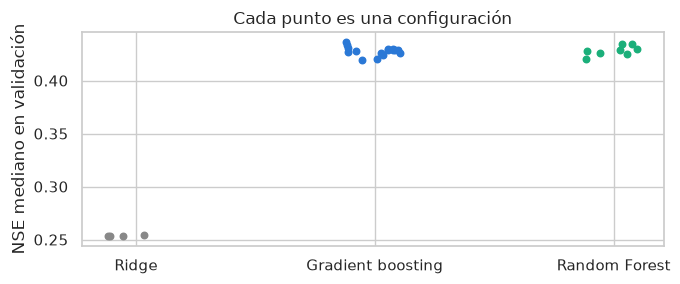

In [2]:
grillas = pd.DataFrame([{"algoritmo": a, "hiperparámetros": "; ".join(f"{k} ∈ {v}" for k, v in g.items()),
                         "configuraciones": int(np.prod([len(v) for v in g.values()]))} for a, (_, g) in mo.ALGORITMOS.items()]).set_index("algoritmo")
grillas["minutos de entrenamiento"] = (busq.groupby("algoritmo").segundos.sum() / 60).round(1)
display(grillas)

b = busq.copy(); b["params"] = b.parametros.map(json.loads)
for a in ALG:
    t = pd.concat([b[b.algoritmo == a].params.apply(pd.Series), b[b.algoritmo == a][["NSE_mediano", "KGE_mediano", "cuencas_NSE_positivo", "segundos"]]], axis=1)
    print(f"\n{a}"); display(t.sort_values("NSE_mediano", ascending=False).round(3).head(8))

fig, ax = plt.subplots(figsize=(7, 3))
for i, a in enumerate(ALG):
    y = busq[busq.algoritmo == a].NSE_mediano
    ax.scatter(np.full(len(y), i) + np.random.default_rng(0).uniform(-.12, .12, len(y)), y, color=COLOR_A[a], s=22)
ax.set(xticks=range(len(ALG)), xticklabels=ALG, ylabel="NSE mediano en validación", title="Cada punto es una configuración")
fig.tight_layout(); fig.savefig(OUT / "fig_busqueda.png", dpi=200); plt.show()

### 1a. Efecto de cada hiperparámetro
NSE mediano promedio de las configuraciones con cada valor (los demás hiperparámetros varían).

In [3]:
for a in ["Gradient boosting", "Random Forest"]:
    t = pd.concat([b[b.algoritmo == a].params.apply(pd.Series), b[b.algoritmo == a].NSE_mediano], axis=1)
    efecto = pd.concat({h: t.groupby(h, dropna=False).NSE_mediano.mean() for h in t.columns if h != "NSE_mediano"})
    print(a); display(efecto.round(3).to_frame("NSE mediano promedio"))

Gradient boosting


NSE mediano promedio
l2_regularization 0.00                   0.427
                  1.00                   0.429
learning_rate     0.05                   0.427
                  0.10                   0.429
max_leaf_nodes    31.00                  0.426
                  127.00                 0.430
min_samples_leaf  20.00                  0.427
                  200.00                 0.429

Random Forest


NSE mediano promedio
max_depth        20.00                 0.427
                 NaN                   0.430
max_features     0.33                  0.431
                 0.66                  0.426
min_samples_leaf 5.00                  0.432
                 50.00                 0.425

**Lectura.** El salto grande está entre familias, no entre hiperparámetros. Ridge da 0,254 con cualquier `alpha`: con casi 500.000 filas la regularización no cambia nada, y lo que lo limita es que la relación entre lluvia y caudal no es lineal. Los dos modelos de árboles suben a 0,42–0,44, unos 0,18 más. Dentro de cada familia las 16 configuraciones de gradient boosting quedan entre 0,419 y 0,436 y las 8 de Random Forest entre 0,420 y 0,435: **mover los hiperparámetros cambia el NSE mediano en menos de 0,02**. Las tendencias son coherentes aunque pequeñas: en gradient boosting ayudan hojas más grandes (`min_samples_leaf` = 200) y más regularización; en Random Forest ayuda usar un tercio de las variables por división, y la profundidad máxima no importa. Las mejores configuraciones son gradient boosting con `learning_rate` 0,05, 127 hojas, `min_samples_leaf` 200 y `l2_regularization` 1, y Random Forest sin límite de profundidad, `max_features` 0,33 y `min_samples_leaf` 5. Random Forest cuesta más del doble: 17 minutos de búsqueda contra 8.

## 2. Selección del algoritmo
La mejor configuración de cada algoritmo pasa por la validación cruzada espacial: se entrena con el periodo de entrenamiento de las cuencas de 4 folds y se evalúa el periodo de validación de las cuencas del fold que quedó fuera. Gana el mayor NSE mediano espacial; si otro algoritmo queda a menos de 0,02, se prefiere el más simple (Ridge < gradient boosting < Random Forest, por tamaño del modelo y costo de predecir).

,configuración,NSE mediano temporal (validación),NSE mediano espacial (validación),KGE mediano espacial,cuencas con NSE espacial > 0
algoritmo,,,,,
Ridge,"{""alpha"": 0.1}",0.254,0.212,0.377,170
Gradient boosting,"{""l2_regularization"": 1, ""learning_rate"": 0.05...",0.436,0.289,0.440,181
Random Forest,"{""max_depth"": null, ""max_features"": 0.33, ""min...",0.435,0.291,0.418,187


NSE mediano espacial por región,Ridge,Gradient boosting,Random Forest
region,,,
Magdalena-Cauca,0.182,0.281,0.264
Orinoco,0.402,0.592,0.540
Caribe,0.144,0.047,0.085
Pacífico,0.186,0.234,0.314
Amazonas,0.257,0.215,0.180


Escogido: Gradient boosting


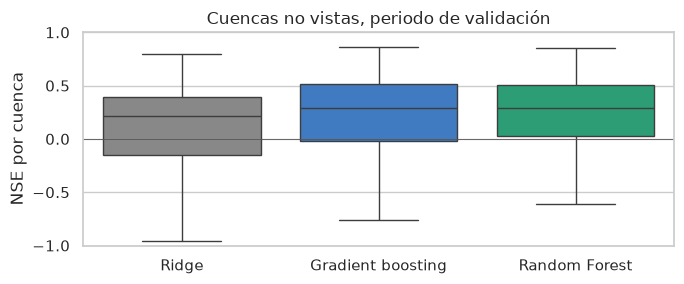

In [4]:
tv = busq.sort_values("NSE_mediano", ascending=False).drop_duplicates("algoritmo").set_index("algoritmo")
res = pd.DataFrame({"configuración": tv.parametros, "NSE mediano temporal (validación)": tv.NSE_mediano,
                    "NSE mediano espacial (validación)": sel.groupby("algoritmo").NSE.median(),
                    "KGE mediano espacial": sel.groupby("algoritmo").KGE.median(),
                    "cuencas con NSE espacial > 0": sel.groupby("algoritmo").NSE.apply(lambda s: int((s > 0).sum()))}).loc[ALG]
display(res.round(3))
reg_sel = sel.join(region, on="gauge_id").pivot_table(index="region", columns="algoritmo", values="NSE", aggfunc="median").loc[ORDEN, ALG]
display(reg_sel.round(3).rename_axis(columns="NSE mediano espacial por región"))
print(f"Escogido: {ELEGIDO}")

fig, ax = plt.subplots(figsize=(7, 3))
sns.boxplot(data=sel, x="algoritmo", y="NSE", order=ALG, hue="algoritmo", palette=COLOR_A, showfliers=False, legend=False, ax=ax)
ax.axhline(0, color="#555", lw=.6); ax.set(ylim=(-1, 1), ylabel="NSE por cuenca", xlabel="", title="Cuencas no vistas, periodo de validación")
fig.tight_layout(); fig.savefig(OUT / "fig_seleccion.png", dpi=200); plt.show()

**Lectura.** En cuencas no vistas Random Forest queda en 0,291 y gradient boosting en 0,289: una diferencia de 0,002, muy por debajo del margen de 0,02 fijado de antemano. Por la regla de desempate gana el más simple, **gradient boosting**, que además entrena unas 3,5 veces más rápido (118 s contra 410 s con todos los datos de entrenamiento + validación). No es una victoria clara: Random Forest tiene 6 cuencas más con NSE espacial positivo (187 contra 181) y es mejor en el Pacífico (0,31 contra 0,23). Los tres algoritmos pierden entre 0,04 y 0,15 de NSE al pasar de cuencas vistas a cuencas no vistas, así que buena parte del error en cuencas nuevas es de transferencia y no de ajuste. Por región, el Orinoco es la más fácil (0,59) y el Caribe la más difícil: ahí gradient boosting (0,05) queda por debajo de Ridge (0,14), igual que en el Amazonas (0,22 contra 0,26), aunque este último tiene solo 11 cuencas.

## 3. Evaluación en prueba (una sola vez)
Con la elección congelada, cada algoritmo se reentrena con entrenamiento + validación y se predice el periodo de prueba. Se reportan los tres para las comparaciones P5 y P7; la elección no cambia.

### 3a. Cuencas con estación (P4: NSE y KGE medianos ≥ 0,70)

In [5]:
mt = mo.metricas(pt, ALG)
tab = pd.concat({a: val.resumir(mt.loc[a], region) for a in ALG}, axis=1).loc[ORDEN + ["Nacional"]]
display(tab.round(3))
mt.reset_index().to_csv(OUT / "metricas_prueba_temporal.csv", index=False)

Ridge                              Gradient boosting         \
                   NSE    KGE   RMSE    MAE cuencas               NSE    KGE   
region                                                                         
Magdalena-Cauca  0.141  0.367  1.776  1.270     136             0.331  0.472   
Orinoco          0.397  0.490  2.382  1.616      37             0.687  0.631   
Caribe           0.117  0.407  2.654  2.111      44             0.302  0.497   
Pacífico         0.312  0.501  2.174  1.425      20             0.501  0.562   
Amazonas         0.263  0.332  2.500  1.794      11             0.429  0.574   
Nacional         0.200  0.396  2.032  1.388     248             0.373  0.499   

                                      Random Forest                       \
                  RMSE    MAE cuencas           NSE    KGE   RMSE    MAE   
region                                                                     
Magdalena-Cauca  1.479  0.973     136         0.344  0.464  1.458  0.976   
Orinoco          1.978  1.312      37         0.680  0.641  1.962  1.289   
Caribe           2.157  1.505      44         0.310  0.481  2.100  1.441   
Pacífico         1.800  0.972      20         0.513  0.544  1.886  1.001   
Amazonas         2.045  1.511      11         0.489  0.544  2.095  1.405   
Nacional         1.735  1.074     248         0.365  0.491  1.723  1.086   

                         
                cuencas  
region                   
Magdalena-Cauca     136  
Orinoco              37  
Caribe               44  
Pacífico             20  
Amazonas             11  
Nacional            248

### 3b. Cuencas sin estación (P6: NSE mediano ≥ 0,50)
Validación cruzada espacial sobre el periodo de prueba, con los folds del ítem 9 y con las dos semillas siguientes mejor equilibradas (solo el modelo escogido).

In [6]:
me = mo.metricas(pe[S0], ALG)
tab_e = pd.concat({a: val.resumir(me.loc[a], region) for a in ALG}, axis=1).loc[ORDEN + ["Nacional"]]
display(tab_e.round(3))
sem = pd.Series({s: pdat.metricas_por_cuenca(p.gauge_id, p.q, p[ELEGIDO]).NSE.median() for s, p in pe.items()}, name=f"NSE mediano espacial ({ELEGIDO})")
display(sem.rename_axis("semilla de los folds").round(3).to_frame())
sin_vecinas = folds.index[folds.aguas_arriba < .05]
print(f"{ELEGIDO}: NSE mediano espacial {me.loc[ELEGIDO].NSE.median():.3f} en las 248 cuencas; "
      f"{me.loc[ELEGIDO].NSE.loc[sin_vecinas].median():.3f} en las {len(sin_vecinas)} sin cuencas de entrenamiento aguas arriba; "
      f"rango entre semillas {sem.min():.3f}–{sem.max():.3f}")
me.reset_index().to_csv(OUT / "metricas_prueba_espacial.csv", index=False)

Ridge                              Gradient boosting         \
                   NSE    KGE   RMSE    MAE cuencas               NSE    KGE   
region                                                                         
Magdalena-Cauca  0.066  0.337  1.839  1.372     136             0.164  0.360   
Orinoco          0.337  0.433  2.507  1.747      37             0.529  0.525   
Caribe           0.013  0.362  3.005  2.225      44             0.156  0.402   
Pacífico         0.233  0.352  2.460  1.782      20             0.304  0.396   
Amazonas         0.252  0.331  3.204  2.297      11             0.132  0.398   
Nacional         0.124  0.351  2.200  1.551     248             0.207  0.385   

                                      Random Forest                       \
                  RMSE    MAE cuencas           NSE    KGE   RMSE    MAE   
region                                                                     
Magdalena-Cauca  1.748  1.210     136         0.168  0.344  1.773  1.232   
Orinoco          2.134  1.374      37         0.525  0.521  2.213  1.404   
Caribe           2.815  1.962      44         0.079  0.397  2.882  2.101   
Pacífico         2.132  1.355      20         0.334  0.388  2.066  1.388   
Amazonas         2.779  1.840      11         0.232  0.373  2.571  1.816   
Nacional         1.975  1.326     248         0.205  0.368  1.970  1.356   

                         
                cuencas  
region                   
Magdalena-Cauca     136  
Orinoco              37  
Caribe               44  
Pacífico             20  
Amazonas             11  
Nacional            248

,NSE mediano espacial (Gradient boosting)
semilla de los folds,
4,0.207
6,0.200
30,0.212


Gradient boosting: NSE mediano espacial 0.207 en las 248 cuencas; 0.198 en las 190 sin cuencas de entrenamiento aguas arriba; rango entre semillas 0.200–0.212


### 3c. ¿Mejora a la regresión lineal? (P5: ≥ 70 % de las cuencas mejoran y mejora mediana ≥ 0,10; prueba t pareada p < 0,05)
El NSE no tiene cota inferior: en una cuenca con caudal casi constante, cualquier error da valores de −30 o −200. Esos pocos valores inflan la varianza y dominan las pruebas paramétricas. Por eso, además de la prueba t planeada, se reporta la misma prueba sobre el NSE acotado $\mathrm{NSE}/(2-\mathrm{NSE})$ (Mathevet et al., 2006), que conserva el orden entre modelos pero queda en $(-1, 1]$, y la de Wilcoxon, que no supone normalidad.

In [7]:
acotar = lambda s: s / (2 - s)
print("Cuencas con NSE < −10 en prueba:", {a: list(mt.loc[a].NSE[mt.loc[a].NSE < -10].round(1).items()) for a in ALG})
filas_p5 = []
for otro in [a for a in ALG if a != ELEGIDO]:
    d = (mt.loc[ELEGIDO].NSE - mt.loc[otro].NSE).dropna()
    e, o = mt.loc[ELEGIDO].NSE.loc[d.index], mt.loc[otro].NSE.loc[d.index]
    filas_p5.append({"comparación": f"{ELEGIDO} − {otro}", "cuencas": len(d), "% de cuencas que mejoran": 100 * (d > 0).mean(),
                     "mejora mediana de NSE": d.median(), "t pareada (p)": stats.ttest_rel(e, o).pvalue,
                     "t pareada, NSE acotado (p)": stats.ttest_rel(acotar(e), acotar(o)).pvalue, "Wilcoxon (p)": stats.wilcoxon(d).pvalue})
display(pd.DataFrame(filas_p5).set_index("comparación").round(4))

Cuencas con NSE < −10 en prueba: {'Ridge': [('15067150', -14.3), ('16057050', -185.7), ('24017820', -224.2), ('24037030', -12.4)], 'Gradient boosting': [('16057050', -35.2), ('24017820', -91.7)], 'Random Forest': [('16057050', -33.4), ('24017820', -68.6)]}


,cuencas,% de cuencas que mejoran,mejora mediana de NSE,t pareada (p),"t pareada, NSE acotado (p)",Wilcoxon (p)
comparación,,,,,,
Gradient boosting − Ridge,248,91.5323,0.1644,0.0521,0.0000,0.0000
Gradient boosting − Random Forest,248,44.3548,-0.0025,0.3266,0.1709,0.0366


### 3d. ¿El desempeño es igual en todas las regiones? (P7: ANOVA, p < 0,05 indica diferencias)
Mismo problema que en P5: el ANOVA se calcula sobre el NSE y sobre el NSE acotado; Kruskal-Wallis compara rangos.

In [8]:
grupos = [mt.loc[ELEGIDO].NSE.loc[region[region == r].index].dropna() for r in ORDEN]
an, an_a, kw = stats.f_oneway(*grupos), stats.f_oneway(*[acotar(g) for g in grupos]), stats.kruskal(*grupos)
print(f"ANOVA F = {an.statistic:.2f}, p = {an.pvalue:.4f}   ANOVA con NSE acotado F = {an_a.statistic:.2f}, p = {an_a.pvalue:.4f}   "
      f"Kruskal-Wallis H = {kw.statistic:.2f}, p = {kw.pvalue:.4f}")
display(pd.DataFrame({"cuencas": [len(g) for g in grupos], "NSE mediano": [g.median() for g in grupos],
                      "p25": [g.quantile(.25) for g in grupos], "p75": [g.quantile(.75) for g in grupos]}, index=ORDEN).round(3))

ANOVA F = 0.30, p = 0.8807   ANOVA con NSE acotado F = 13.92, p = 0.0000   Kruskal-Wallis H = 40.51, p = 0.0000


,cuencas,NSE mediano,p25,p75
Magdalena-Cauca,136,0.331,0.184,0.441
Orinoco,37,0.687,0.386,0.800
Caribe,44,0.302,0.204,0.424
Pacífico,20,0.501,0.393,0.575
Amazonas,11,0.429,0.307,0.617


### 3e. Crecientes (P9: recall ≥ 0,70 y precisión ≥ 0,50) y volumen mensual
Un día es de creciente si el caudal supera el percentil 95 del periodo de entrenamiento de su cuenca. Recall: de los días de creciente observados, qué parte el modelo también pone sobre el umbral. Precisión: de los días que el modelo pone sobre el umbral, qué parte fue creciente. El error de volumen mensual es $|\sum \hat q / \sum q - 1|$ por mes (meses con al menos 25 días), resumido con la mediana de cada cuenca.

In [9]:
umbral = mo.umbral_creciente(X)
filas_c = []
for a in ALG:
    c = mo.crecientes(pt, a, umbral); v = mo.error_volumen_mensual(pt, a)
    filas_c.append({"algoritmo": a, "recall mediano": c.recall.median(), "precisión mediana": c.precision.median(),
                    "cuencas con recall ≥ 0,70": int((c.recall >= .7).sum()), "error de volumen mensual mediano": v.median(),
                    "% de cuencas con error de volumen ≤ 15 %": 100 * (v <= .15).mean()})
display(pd.DataFrame(filas_c).set_index("algoritmo").round(3))
print(f"Días de creciente en prueba: {int(mo.crecientes(pt, ELEGIDO, umbral).dias_creciente.sum()):,}")

,recall mediano,precisión mediana,"cuencas con recall ≥ 0,70",error de volumen mensual mediano,% de cuencas con error de volumen ≤ 15 %
algoritmo,,,,,
Ridge,0.079,0.411,15,0.305,5.263
Gradient boosting,0.166,0.500,4,0.212,24.696
Random Forest,0.154,0.500,3,0.222,24.291


Días de creciente en prueba: 31,222


### 3f. ¿La calidad de la lluvia limita el desempeño? (P8)
P8 preguntaba por las cuencas con coeficiente de escorrentía mayor que 1 (más caudal que lluvia), un síntoma de lluvia satelital subestimada. Esas 55 cuencas se descartaron en la limpieza, así que la prueba de Welch planeada no se puede hacer. Se mide lo más cercano: la correlación entre el NSE de cada cuenca y su coeficiente de escorrentía.

In [10]:
firmas = pd.read_csv(RAIZ / "Camels col/09_CAMELS_COL_Hydrological_signatures.csv").set_index("gauge_id")
firmas.index = firmas.index.astype(str)
rr = firmas.runoff_ratio.loc[mt.loc[ELEGIDO].index]
rho = stats.spearmanr(rr, mt.loc[ELEGIDO].NSE)
alto = rr > rr.quantile(.75)
w = stats.ttest_ind(mt.loc[ELEGIDO].NSE[alto], mt.loc[ELEGIDO].NSE[~alto], equal_var=False)
print(f"Spearman ρ(NSE, coeficiente de escorrentía) = {rho.statistic:.3f} (p = {rho.pvalue:.4f})")
print(f"NSE mediano con coeficiente en el cuartil superior: {mt.loc[ELEGIDO].NSE[alto].median():.3f}; resto: {mt.loc[ELEGIDO].NSE[~alto].median():.3f}; Welch p = {w.pvalue:.4f}")

Spearman ρ(NSE, coeficiente de escorrentía) = 0.088 (p = 0.1686)
NSE mediano con coeficiente en el cuartil superior: 0.365; resto: 0.374; Welch p = 0.1774


### 3g. Resumen de KPIs

In [11]:
c_el = mo.crecientes(pt, ELEGIDO, umbral)
d_lin = (mt.loc[ELEGIDO].NSE - mt.loc["Ridge"].NSE).dropna()
kpi = pd.DataFrame([
    ("P4: NSE mediano, cuencas con estación", "≥ 0,70", mt.loc[ELEGIDO].NSE.median(), mt.loc[ELEGIDO].NSE.median() >= .7),
    ("P4: KGE mediano, cuencas con estación", "≥ 0,70", mt.loc[ELEGIDO].KGE.median(), mt.loc[ELEGIDO].KGE.median() >= .7),
    ("P6: NSE mediano, cuencas sin estación", "≥ 0,50", me.loc[ELEGIDO].NSE.median(), me.loc[ELEGIDO].NSE.median() >= .5),
    ("P5: % de cuencas que mejoran frente a Ridge", "≥ 70 %", 100 * (d_lin > 0).mean(), (d_lin > 0).mean() >= .7),
    ("P5: mejora mediana del NSE frente a Ridge", "≥ 0,10", d_lin.median(), d_lin.median() >= .1),
    ("P5: t pareada frente a Ridge (p), NSE", "< 0,05", filas_p5[0]["t pareada (p)"], filas_p5[0]["t pareada (p)"] < .05),
    ("P5: t pareada frente a Ridge (p), NSE acotado", "< 0,05", filas_p5[0]["t pareada, NSE acotado (p)"], filas_p5[0]["t pareada, NSE acotado (p)"] < .05),
    ("P9: recall mediano de crecientes", "≥ 0,70", c_el.recall.median(), c_el.recall.median() >= .7),
    ("P9: precisión mediana de crecientes", "≥ 0,50", c_el.precision.median(), c_el.precision.median() >= .5),
], columns=["KPI", "meta", "resultado", "¿cumple?"]).set_index("KPI")
kpi["¿cumple?"] = kpi["¿cumple?"].map({True: "sí", False: "no"})
display(kpi.round(3))
kpi.to_csv(OUT / "kpis.csv")

,meta,resultado,¿cumple?
KPI,,,
"P4: NSE mediano, cuencas con estación","≥ 0,70",0.373,no
"P4: KGE mediano, cuencas con estación","≥ 0,70",0.499,no
"P6: NSE mediano, cuencas sin estación","≥ 0,50",0.207,no
P5: % de cuencas que mejoran frente a Ridge,≥ 70 %,91.532,sí
P5: mejora mediana del NSE frente a Ridge,"≥ 0,10",0.164,sí
"P5: t pareada frente a Ridge (p), NSE","< 0,05",0.052,no
"P5: t pareada frente a Ridge (p), NSE acotado","< 0,05",0.000,sí
P9: recall mediano de crecientes,"≥ 0,70",0.166,no
P9: precisión mediana de crecientes,"≥ 0,50",0.500,sí


**Lectura.** El modelo cumple la comparación contra la línea base, pero no las metas absolutas del primer reporte.

- **P4 no se cumple.** En cuencas con estación el NSE mediano en prueba es 0,373 y el KGE mediano 0,499, lejos de 0,70. Solo el Orinoco se acerca (NSE 0,687); el Pacífico llega a 0,50 y el Magdalena-Cauca y el Caribe se quedan en 0,33 y 0,30. El 91 % de las cuencas tiene NSE positivo, es decir, el modelo casi siempre es mejor que predecir el promedio, pero no reproduce bien la variación diaria.
- **P6 no se cumple.** En cuencas sin estación el NSE mediano es 0,207, contra 0,124 de Ridge. El resultado es estable: con los folds de las tres semillas mejor equilibradas va de 0,200 a 0,212, y en las 190 cuencas sin cuencas de entrenamiento aguas arriba es 0,198, así que no depende de cuencas anidadas. Es menor que en la validación espacial (0,289), lo que muestra cuánto cambia el resultado de un periodo a otro.
- **P5 se cumple en lo práctico.** El 91,5 % de las cuencas mejora frente a Ridge, con una mejora mediana de 0,164. La prueba t planeada da p = 0,052, justo por encima de 0,05, pero eso se debe a dos cuencas con caudal casi constante (24017820 y 16057050, con unos 0,1 mm/día de media) donde Ridge tiene NSE de −224 y −186. Con el NSE acotado la prueba t da p < 0,0001, y Wilcoxon también. Frente a Random Forest no hay diferencia útil: mejora mediana de −0,003 y t pareada p = 0,33.
- **P7: el desempeño sí cambia entre regiones.** ANOVA con NSE acotado F = 13,9 y Kruskal-Wallis H = 40,5, ambos con p < 0,0001. El ANOVA sobre el NSE sin acotar (p = 0,88) no es confiable por las mismas dos cuencas.
- **P9 se cumple a medias.** La precisión mediana es 0,50, en el límite, pero el recall mediano es 0,17: el modelo rara vez pasa el umbral de creciente porque se queda corto en los picos (sección 4). El error de volumen mensual mediano es 21 % y solo el 25 % de las cuencas queda en 15 % o menos.
- **P8.** El NSE no se relaciona con el coeficiente de escorrentía (ρ = 0,09, p = 0,17), así que entre las cuencas conservadas la calidad de la lluvia, medida así, no explica el desempeño. Las cuencas con coeficiente mayor que 1 se descartaron antes de modelar, por lo que la pregunta original no se puede responder.

## 4. Evaluación cualitativa
### 4a. Hidrogramas
Tres cuencas del periodo de prueba: la del percentil 10, la mediana y la del percentil 90 del NSE del modelo escogido. Se muestran los últimos 730 días con datos; los huecos de la serie quedan en blanco.

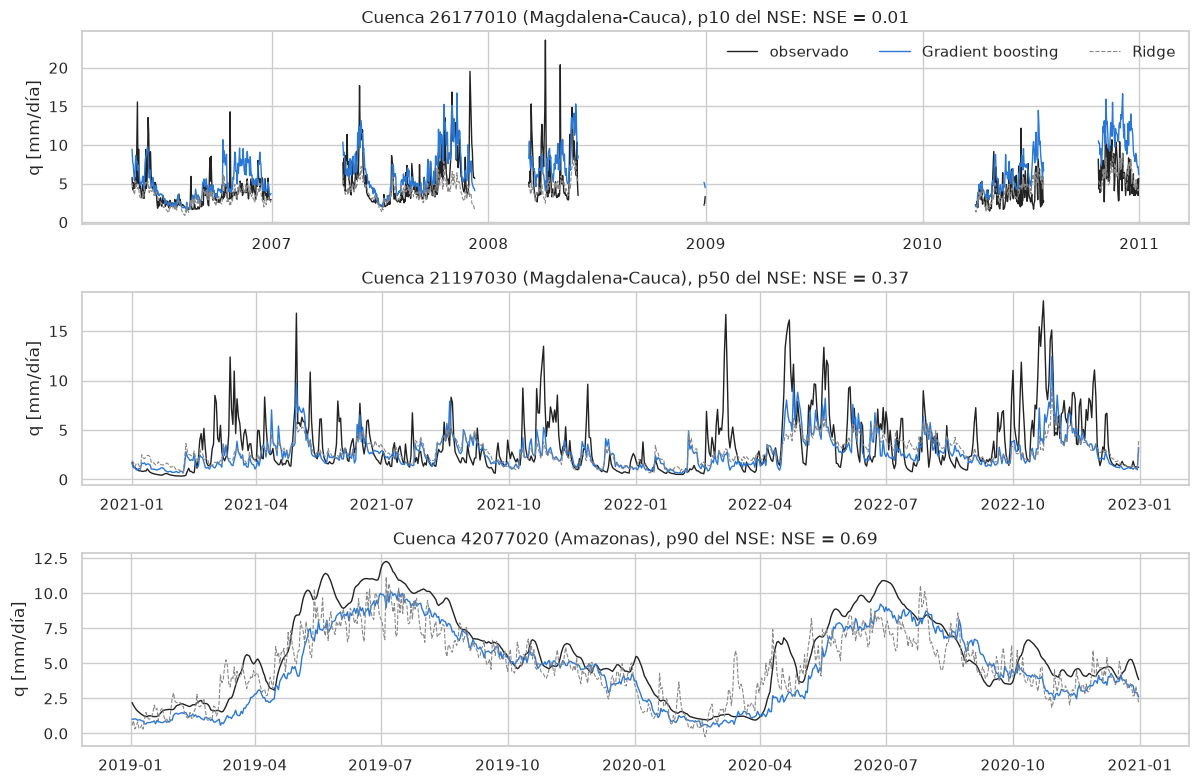

In [12]:
nse_el = mt.loc[ELEGIDO].NSE.dropna().sort_values()
casos = {f"p{int(q * 100)}": nse_el.index[int(q * (len(nse_el) - 1))] for q in (.1, .5, .9)}
fig, ax = plt.subplots(3, 1, figsize=(12, 8))
for a_, (et, g) in zip(ax, casos.items()):
    d = pt[pt.gauge_id == g].set_index("Fecha").sort_index()
    d = d.iloc[-730:].asfreq("D")
    a_.plot(d.index, d.q, color="#222", lw=1, label="observado")
    a_.plot(d.index, d[ELEGIDO], color=COLOR_A[ELEGIDO], lw=1, label=ELEGIDO)
    a_.plot(d.index, d["Ridge"], color=COLOR_A["Ridge"], lw=.8, ls="--", label="Ridge")
    a_.set(ylabel="q [mm/día]", title=f"Cuenca {g} ({region[g]}), {et} del NSE: NSE = {nse_el[g]:.2f}")
ax[0].legend(frameon=False, ncol=3)
fig.tight_layout(); fig.savefig(OUT / "fig_hidrogramas.png", dpi=200); plt.show()

### 4b. Caudales altos y bajos
Para cada cuenca se compara la curva de duración de caudales estimada con la observada: el cociente estimado / observado en el caudal que se supera el 1 %, 5 %, 50 % y 95 % del tiempo. Un cociente menor que 1 indica que el modelo se queda corto.

,Ridge,Gradient boosting,Random Forest
cociente estimado / observado (mediana entre cuencas),,,
Q1 (crecientes),0.693,0.734,0.738
Q5,0.797,0.835,0.823
Q50 (mediana),1.129,1.083,1.101
Q95 (estiaje),0.740,1.290,1.337


% de días de prueba con caudal estimado negativo: {'Ridge': 4.78, 'Gradient boosting': 0.06, 'Random Forest': 0.0}


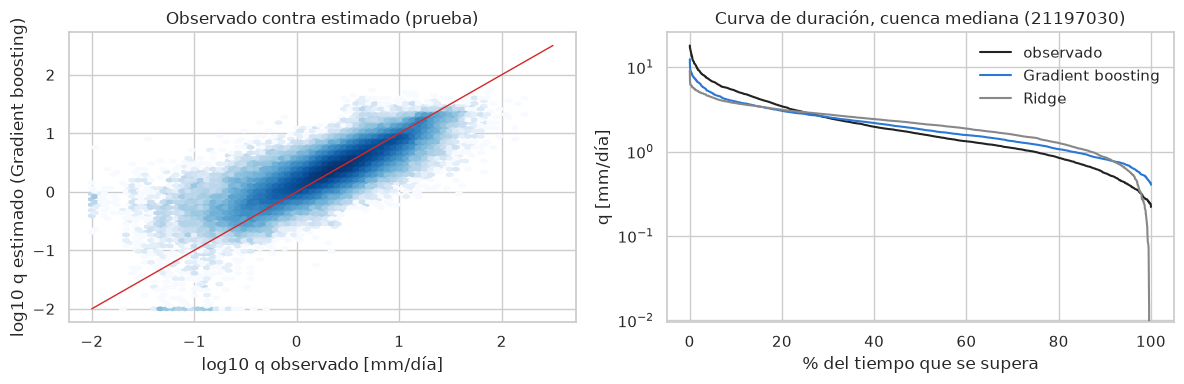

In [13]:
PROB = {"Q1 (crecientes)": .99, "Q5": .95, "Q50 (mediana)": .5, "Q95 (estiaje)": .05}
dur = []
for g, d in pt.groupby("gauge_id"):
    for et, p in PROB.items():
        o = d.q.quantile(p)
        dur.append({"gauge_id": g, "caudal": et, **{a: d[a].quantile(p) / o if o > 0 else np.nan for a in ALG}})
dur = pd.DataFrame(dur)
display(dur.groupby("caudal", sort=False)[ALG].median().round(3).rename_axis("cociente estimado / observado (mediana entre cuencas)"))
print("% de días de prueba con caudal estimado negativo:", {a: round(float(100 * (pt[a] < 0).mean()), 2) for a in ALG})

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
m = pt.sample(200_000, random_state=0)
ax[0].hexbin(np.log10(m.q.clip(lower=1e-2)), np.log10(m[ELEGIDO].clip(lower=1e-2)), gridsize=70, bins="log", cmap="Blues")
ax[0].plot([-2, 2.5], [-2, 2.5], color="#d62728", lw=1)
ax[0].set(xlabel="log10 q observado [mm/día]", ylabel=f"log10 q estimado ({ELEGIDO})", title="Observado contra estimado (prueba)")
g = casos["p50"]; d = pt[pt.gauge_id == g]
for col, c, et in [("q", "#222", "observado"), (ELEGIDO, COLOR_A[ELEGIDO], ELEGIDO), ("Ridge", COLOR_A["Ridge"], "Ridge")]:
    x = np.sort(d[col].to_numpy())[::-1]; ax[1].plot(100 * np.arange(1, len(x) + 1) / len(x), x, color=c, label=et)
ax[1].set(yscale="log", xlabel="% del tiempo que se supera", ylabel="q [mm/día]", title=f"Curva de duración, cuenca mediana ({g})"); ax[1].legend(frameon=False)
fig.tight_layout(); fig.savefig(OUT / "fig_observado_estimado.png", dpi=200); plt.show()

### 4c. Régimen mensual por región
Caudal específico medio de cada mes en el periodo de prueba: observado contra estimado.

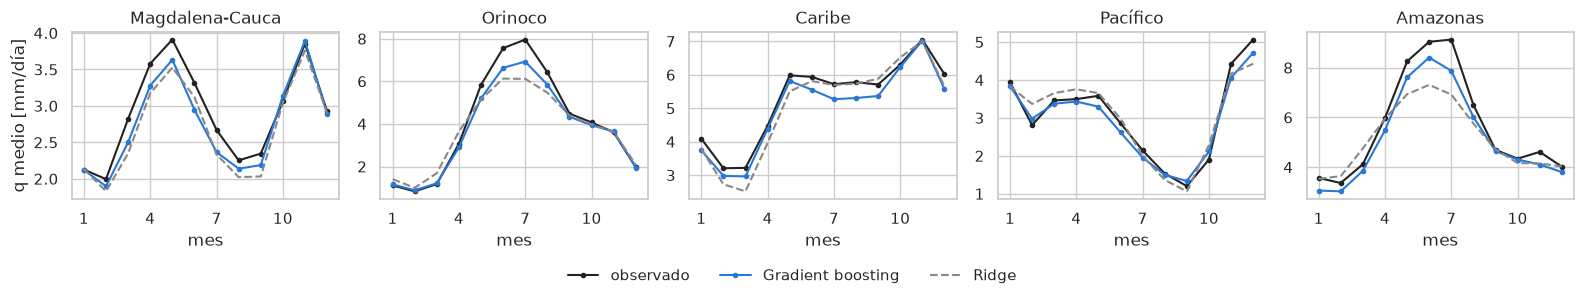

In [14]:
r = pt.assign(region=pt.gauge_id.map(region), mes=pt.Fecha.dt.month).groupby(["region", "mes"])[["q", ELEGIDO, "Ridge"]].mean()
fig, ax = plt.subplots(1, 5, figsize=(16, 3), sharey=False)
for a_, reg in zip(ax, ORDEN):
    x = r.loc[reg]
    a_.plot(x.index, x.q, "o-", color="#222", label="observado", ms=3); a_.plot(x.index, x[ELEGIDO], "o-", color=COLOR_A[ELEGIDO], label=ELEGIDO, ms=3)
    a_.plot(x.index, x["Ridge"], "--", color=COLOR_A["Ridge"], label="Ridge"); a_.set(title=reg, xticks=[1, 4, 7, 10], xlabel="mes")
ax[0].set_ylabel("q medio [mm/día]")
fig.legend(*ax[0].get_legend_handles_labels(), loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(.5, -.02))
fig.tight_layout(rect=(0, .08, 1, 1)); fig.savefig(OUT / "fig_regimen_mensual.png", dpi=200, bbox_inches="tight"); plt.show()

### 4d. Dónde funciona mejor el modelo

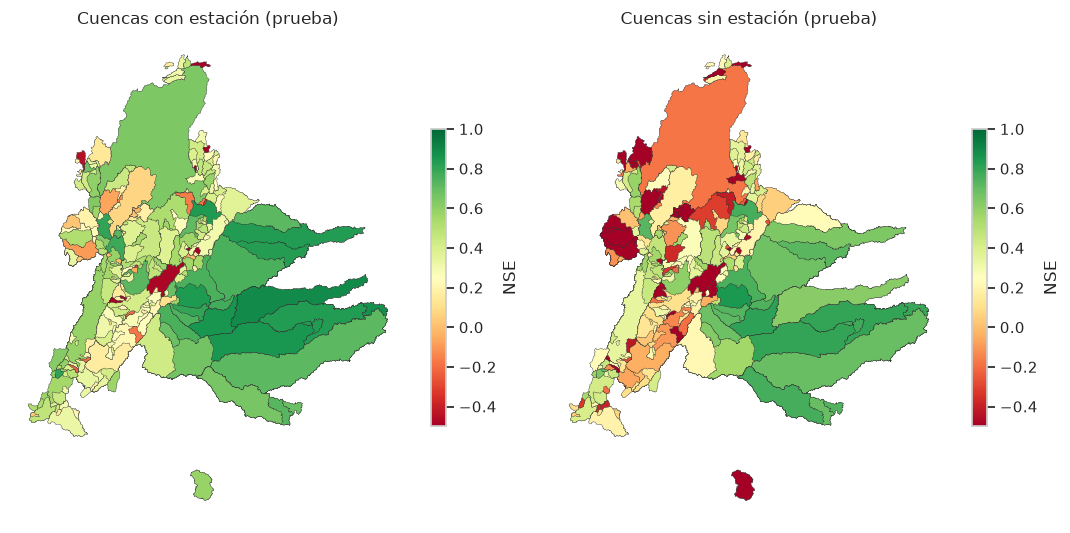

,ρ de Spearman con el NSE (prueba)
aridez,-0.168
log_area,0.508
mean_ele,-0.189
forest_perc,-0.046


In [15]:
poli = val.poligonos(list(est.index)).join(mt.loc[ELEGIDO].NSE.rename("NSE_temporal")).join(me.loc[ELEGIDO].NSE.rename("NSE_espacial"))
poli = poli.sort_values("area_km2", ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(11, 5.5))
for a_, col, t in [(ax[0], "NSE_temporal", "Cuencas con estación (prueba)"), (ax[1], "NSE_espacial", "Cuencas sin estación (prueba)")]:
    poli.plot(ax=a_, column=poli[col].clip(-0.5, 1), cmap="RdYlGn", vmin=-0.5, vmax=1, edgecolor="#333", lw=.2, legend=True, legend_kwds={"shrink": .6, "label": "NSE"})
    a_.set(title=t); a_.set_axis_off()
fig.tight_layout(); fig.savefig(OUT / "fig_mapa_nse.png", dpi=200); plt.show()
atr = est[["aridez", "log_area", "mean_ele", "forest_perc"]].join(mt.loc[ELEGIDO].NSE)
display(atr.corr(method="spearman").NSE.drop("NSE").round(3).to_frame("ρ de Spearman con el NSE (prueba)"))

### 4e. Qué variables usa el modelo
Importancia por permutación en 30.000 días de prueba: cuánto baja el $R^2$ al desordenar cada variable.

Suma de importancias: de la serie 0.467; de la cuenca 0.107


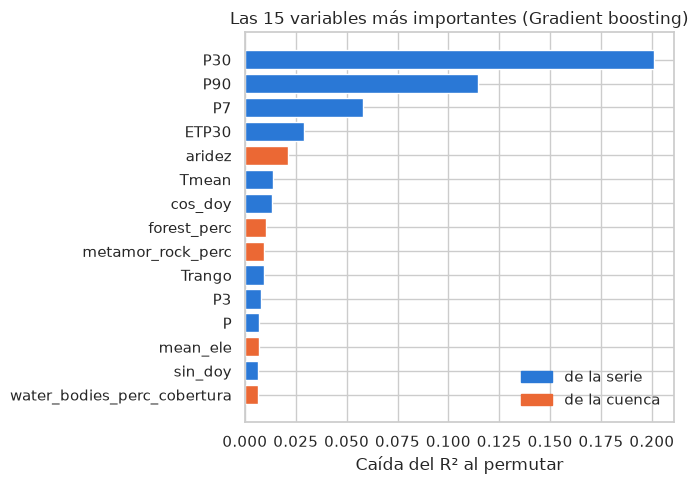

In [16]:
fin = joblib.load(OUT / "modelo_final.joblib")
cols = fin["columnas"]
mu = X[X.particion == "prueba"].sample(30_000, random_state=0)
imp = permutation_importance(fin["modelo"], mu[cols], mu.q, n_repeats=3, random_state=0, n_jobs=1)
imp = pd.Series(imp.importances_mean, index=cols).sort_values(ascending=False)
tipo = np.where(imp.index.isin(pdat.DINAMICAS), "de la serie (diaria)", "de la cuenca (estática)")
print(f"Suma de importancias: de la serie {imp[tipo == 'de la serie (diaria)'].sum():.3f}; de la cuenca {imp[tipo != 'de la serie (diaria)'].sum():.3f}")
fig, ax = plt.subplots(figsize=(7, 5))
top = imp.head(15)[::-1]
ax.barh(top.index, top.values, color=["#2a78d6" if v in pdat.DINAMICAS else "#eb6834" for v in top.index])
ax.set(xlabel="Caída del R² al permutar", title=f"Las 15 variables más importantes ({ELEGIDO})")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color="#2a78d6"), plt.Rectangle((0, 0), 1, 1, color="#eb6834")], labels=["de la serie", "de la cuenca"], frameon=False, loc="lower right")
fig.tight_layout(); fig.savefig(OUT / "fig_importancia.png", dpi=200); plt.show()

**Lectura.** Las cuatro vistas cuentan lo mismo: **el modelo reproduce el régimen pero aplana los extremos.**

- **Hidrogramas.** En la cuenca del percentil 90 (Amazonas, NSE 0,69) sigue bien el ciclo anual y se queda corto en el pico de mitad de año. En la mediana (Magdalena-Cauca, NSE 0,37) acierta cuándo ocurren los eventos, pero los picos observados de 15–17 mm/día quedan en unos 8. En la del percentil 10 (Magdalena-Cauca, NSE 0,01) sobreestima de forma sostenida en la segunda temporada de lluvias de 2006, 2007 y 2010, mientras deja pasar picos aislados de más de 15 mm/día. La serie tiene huecos largos, así que la prueba de esa cuenca cubre pocos años.
- **Curvas de duración.** En la cuenca típica, el caudal que se supera el 1 % del tiempo queda en 73 % del observado y el del 5 % en 84 %, mientras que el estiaje (Q95) queda 29 % por encima. El modelo comprime la distribución hacia el medio. Ridge además produce caudales negativos en el 4,8 % de los días; gradient boosting casi nunca (0,06 %).
- **Régimen mensual.** El modelo capta el régimen bimodal andino (Magdalena-Cauca, Caribe, Pacífico) y el unimodal de los Llanos y la Amazonía, pero queda por debajo en los meses más húmedos: alrededor de un 10 % en el pico de junio y julio del Orinoco y el Amazonas.
- **Mapas.** Funciona mejor en las cuencas grandes de la Orinoquía y la Amazonía y peor en las pequeñas de la cordillera y del Caribe. El NSE crece con el área (ρ de Spearman = 0,51) y baja un poco con la aridez (−0,17). En cuencas no vistas el contraste se acentúa: varias cuencas andinas y del Caribe quedan con NSE negativo.
- **Importancia.** Las variables más usadas son la lluvia acumulada de 30 y 90 días (P30 y P90) y la de 7 días. La lluvia del mismo día (P) casi no se usa (0,007). Eso explica los picos recortados: el modelo aprende la humedad de fondo de la cuenca, no la respuesta a un aguacero. Los atributos de la cuenca suman 0,107 de importancia contra 0,467 de las variables diarias; con tan poco peso en lo que distingue a una cuenca de otra, la transferencia a cuencas no vistas es débil.

## 5. Oportunidades de mejora
Ordenadas por el problema que atacan; las primeras son las de menor costo.

1. **Picos recortados y estiajes sobreestimados.** Entrenar sobre $\log(q + \varepsilon)$ o $\sqrt{q}$ en lugar de $q$, o ponderar más los días altos en la pérdida. El caudal tiene cola pesada y el error cuadrático empuja las predicciones hacia el medio, que es lo que muestran las curvas de duración. Con la transformación logarítmica tampoco habría caudales negativos.
2. **Respuesta a eventos de lluvia.** Agregar entradas que describan aguaceros y no solo acumulados: lluvia de los dos o tres días anteriores por separado, máximo de 3 días, intensidad, y un índice de humedad antecedente con decaimiento ajustado al tiempo de respuesta de la cuenca (que depende del área y la pendiente). Hoy la lluvia del día casi no se usa, y de eso depende el recall de crecientes (P9).
3. **Cuencas no vistas (P6).** El modelo usa poco los atributos estáticos. Hay dos caminos: predecir el caudal normalizado por la media de largo plazo de la cuenca y estimar esa media aparte a partir de los atributos (regionalización en dos etapas), o entrenar modelos por región, donde el Orinoco ya funciona bien. El Caribe y el Amazonas tienen pocas cuencas (44 y 11) y necesitan más estaciones.
4. **Cuencas con caudal casi constante.** Las cuencas 24017820 y 16057050 devuelven como caudal solo el 6 % y el 5 % de la lluvia, posible señal de regulación o extracciones, y ninguna de las seis banderas de la limpieza las marca. Conviene agregar una bandera para coeficientes de escorrentía muy bajos y revisarlas antes de decidir si se sacan. Para los KPIs conviene reportar también el NSE acotado o el KGE, que no se rompen con estos casos.
5. **Modelo secuencial.** En la literatura de CAMELS, las redes recurrentes (LSTM) alcanzan NSE medianos cercanos a 0,7 porque aprenden la memoria de la cuenca sin variables acumuladas hechas a mano. No se entrenó porque no se vio en el curso; queda sujeto a la aprobación del profesor.
6. **Metas de los KPIs.** Las metas P4 y P6 (0,70 y 0,50) venían de esos modelos secuenciales. Para un modelo tabular sin caudal rezagado, como este, metas más realistas serían NSE alrededor de 0,5 en cuencas con estación y 0,3 sin estación. Conviene revisarlas con el cliente antes de decidir si el modelo sirve para el producto de datos.
7. **Búsqueda de hiperparámetros.** Como los hiperparámetros movieron el NSE menos de 0,02, el esfuerzo rinde más en variables y en la transformación del objetivo que en grillas más grandes.

## 6. Lo que pide el ítem 10

| Lo que pide la rúbrica | Dónde |
|---|---|
| Al menos tres algoritmos | Ridge, gradient boosting y Random Forest (sección 1) |
| Diferentes conjuntos de hiperparámetros | 28 configuraciones (sección 1) |
| Evaluación cuantitativa con las métricas del enfoque analítico | NSE, KGE, RMSE y MAE por cuenca; KPIs P4 a P9 (sección 3) |
| Evaluación cualitativa complementaria | hidrogramas, curvas de duración, régimen mensual, mapas e importancia de variables (sección 4) |
| Oportunidades de mejora | sección 5 |

El modelo escogido, entrenado con entrenamiento + validación de las 248 cuencas, está en `salidas/modelos/modelo_final.joblib` (con la lista de columnas) para el producto de datos (ítem 11).